In [345]:
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import v2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path 

In [346]:
DIR = Path("../data/cases_weather_by_region")

def region_key(path):
    """Normalised region name so 'AMNAT CHAROEN' and 'AMNAT_CHAROEN' match."""
    return path.stem.strip().upper().replace(" ", "_")

files = {region_key(p): p for p in sorted(DIR.glob("*.csv"))}
regions = sorted(files.keys())

In [347]:
# import data 
df_dict = {}

for region, path in files.items():
    df = pd.read_csv(path)
    df.drop(columns=[f"valid_time_w{i}" for i in range(1, 5)], inplace=True)
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    
    # Format to datetime
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)

    df_dict[region] = df

for region, df in df_dict.items():
    print(f"Region: {region}")
    print("DataFrame shape:", df.shape)

Region: AMNAT_CHAROEN
DataFrame shape: (240, 14)
Region: ANG_THONG
DataFrame shape: (360, 14)
Region: BANGKOK
DataFrame shape: (360, 14)
Region: BUNGKAN
DataFrame shape: (144, 14)
Region: BURIRAM
DataFrame shape: (360, 14)
Region: CHACHOENGSAO
DataFrame shape: (360, 14)
Region: CHAINAT
DataFrame shape: (360, 14)
Region: CHAIYAPHUM
DataFrame shape: (360, 14)
Region: CHANTHABURI
DataFrame shape: (360, 14)
Region: CHIANG_MAI
DataFrame shape: (360, 14)
Region: CHIANG_RAI
DataFrame shape: (360, 14)
Region: CHONBURI
DataFrame shape: (360, 14)
Region: CHUMPHON
DataFrame shape: (360, 14)
Region: KALASIN
DataFrame shape: (360, 14)
Region: KAMPAENG_PHET
DataFrame shape: (360, 14)
Region: KANCHANABURI
DataFrame shape: (360, 14)
Region: KHON_KAEN
DataFrame shape: (360, 14)
Region: KRABI
DataFrame shape: (360, 14)
Region: LAMPANG
DataFrame shape: (360, 14)
Region: LAMPHUN
DataFrame shape: (360, 14)
Region: LOEI
DataFrame shape: (360, 14)
Region: LOPBURI
DataFrame shape: (360, 14)
Region: MAE_HONG_S

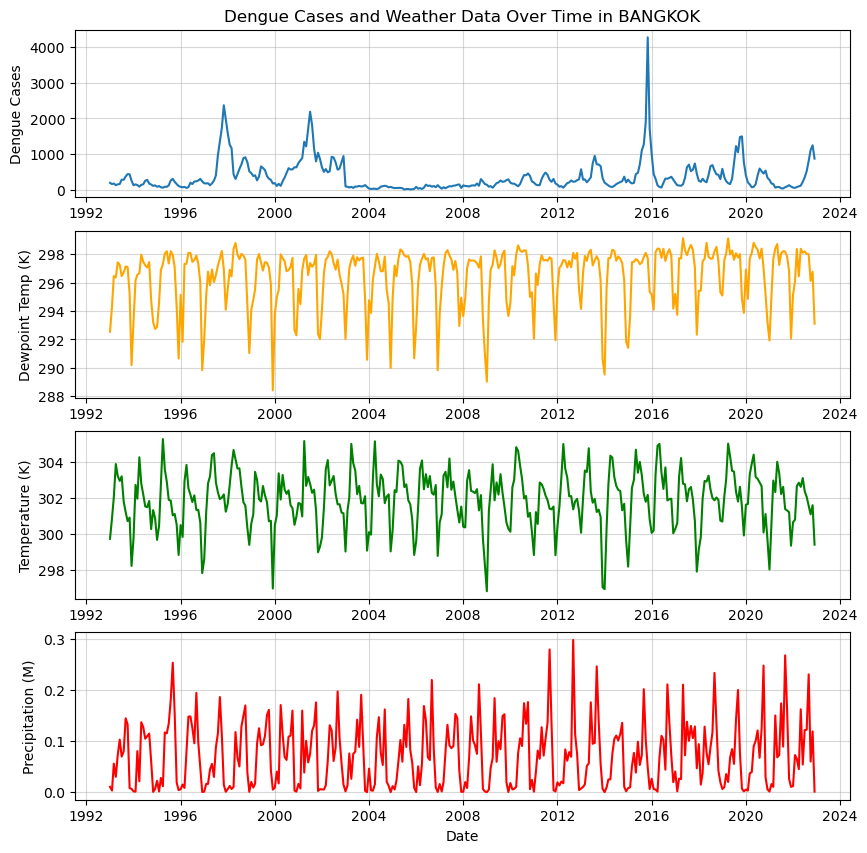

In [348]:
# Plot dengue cases over time along with weather data in a region
REGION = "BANGKOK"
df = df_dict[REGION]

fig, ax = plt.subplots(4, 1, figsize=(10, 10))
ax[0].plot(df["date"], df["dengue_total"],
           label="Total Cases")
ax[1].plot(df["date"], 
           np.mean([df[f"d2m_w{i}"] for i in range(1, 4)], axis=0),
           color="orange",
           label="2m Dewpoint temperature")
ax[2].plot(df["date"], 
           np.mean([df[f"t2m_w{i}"] for i in range(1, 4)], axis=0),
           color="green",
           label="2m Temperature")
ax[3].plot(df["date"], 
           np.sum([df[f"tp_w{i}"] for i in range(1, 4)], axis=0),
           color="red",
           label="Total Precipitation")
ax[3].set_xlabel("Date")
ax[0].set_ylabel("Dengue Cases")
ax[1].set_ylabel("Dewpoint Temp (K)")
ax[2].set_ylabel("Temperature (K)")
ax[3].set_ylabel("Precipitation (M)")
ax[0].set_title(f"Dengue Cases and Weather Data Over Time in {REGION}")
for a in ax:
    a.grid(True, alpha=0.5)
plt.show()

We will create a custom Pytorch Dataset that generates the appropriate input and target vectors.  For a window beginning at week $m$, we'll observe 9 months of historical weather data and historical Dengue cases. I.e.
$$
X_t = 
\begin{bmatrix}
    W_{m-8} & D_{m-8} \\
    W_{m-7} & D_{m-7} \\
    \vdots & \vdots \\
    W_{m} & D_{m}
\end{bmatrix}
$$
where $W_t$ represents the weather variables, and $D_t$ represents the historical monthly Dengue count.  The target is 
$$
Y_t = \begin{bmatrix}
    D_{m+1} & \cdots & D_{m+6}
\end{bmatrix}^\top
$$
where $m$ is the month containing the final week of the input window. Note that $X_t$ will be a $9\times 13$ matrix, and $Y_t$ will be in $\mathbb{R}^6$. 

In [349]:
X = []
Y = []

window_size = 9
forecast_months = 6
step_size = window_size + forecast_months

weather_cols = [
    col for col in df.columns
    if col not in ["date", "dengue_total"]
]

input_cols = weather_cols + ["dengue_total"]
for region, df in df_dict.items():

    monthly_cases = (
        df.assign(month=df["date"].dt.to_period("M"))
        .drop_duplicates("month")
        .dropna()
        .set_index("month")["dengue_total"]
        .sort_index()
    )
    
    for i in range(0, len(df) - window_size + 1, step_size): 

        window = df.iloc[i:i+window_size]

        last_month = df["date"].iloc[i + window_size - 1].to_period("M")

        target_periods = pd.period_range(
            start=last_month + 1,
            periods=forecast_months,
            freq="M"
        )

        if not target_periods.isin(monthly_cases.index).all():
            continue

        x = window[input_cols].to_numpy(dtype=np.float32)

        y = monthly_cases.loc[target_periods].to_numpy(dtype=np.float32)

        X.append(x)
        Y.append(y)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.float32)

print(X.shape, Y.shape)


(1801, 9, 13) (1801, 6)


In [350]:
# Perform train-test split

train_fraction = 0.8
train_size = int(train_fraction * len(X))
X_train, X_test = X[:train_size], X[train_size:]
Y_train, Y_test = Y[:train_size], Y[train_size:]

print(X_train.shape, X_test.shape)
print(Y_train.shape, Y_test.shape)

(1440, 9, 13) (361, 9, 13)
(1440, 6) (361, 6)


In [351]:
class DengueDataset(Dataset):

    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

    def __repr__(self):
        return f"DengueDataset(X={self.X.shape}, Y={self.Y.shape})" 

In [352]:
# Standardize X using training data 
mean_x = X_train.mean(axis=(0,1), keepdims=True)
std_x = X_train.std(axis=(0,1), keepdims=True)
X_train = (X_train - mean_x) / std_x
X_test = (X_test - mean_x) / std_x

# Standardize Y using training data
mean_y = Y_train.mean()
std_y = Y_train.std()
Y_train = (Y_train - mean_y) / std_y
Y_test = (Y_test - mean_y) / std_y

In [353]:
# Create data sets for training and testing
train_dataset = DengueDataset(X_train, Y_train)
test_dataset = DengueDataset(X_test, Y_test)

# Create data loaders for training and testing
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

print(repr(train_dataset))
print(repr(test_dataset))

DengueDataset(X=torch.Size([1440, 9, 13]), Y=torch.Size([1440, 6]))
DengueDataset(X=torch.Size([361, 9, 13]), Y=torch.Size([361, 6]))


In [354]:
# Choose the device for training the neural network
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


In [355]:
# Define the neural network architecture
class NeuralNetwork(nn.Module):
    def __init__(self, nfeatures, nforecast, hiddenlayersizes):
        nhiddenlayers = len(hiddenlayersizes)
        super().__init__()
        self.flatten = nn.Flatten()
        layers = []
        input_dim = nfeatures
        for hidden_dim in hiddenlayersizes:
            layers.append(nn.Linear(input_dim, hidden_dim))
            layers.append(nn.ReLU())
            input_dim = hidden_dim
        layers.append(nn.Linear(input_dim, nforecast))
        self.linear_relu_stack = nn.Sequential(*layers)

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [356]:
# Dimensions
nfeatures = X_train.shape[1] * X_train.shape[2]
nforecast = Y_train.shape[1]

hiddenlayersizes = [256, 128, 64, 32]

# Initialize model
model = NeuralNetwork(
    nfeatures= nfeatures,
    nforecast=nforecast,
    hiddenlayersizes=hiddenlayersizes
)

# Loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)


NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=117, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [357]:
# Hyperparameters
num_epochs = 500

train_losses = []
test_losses = []

for epoch in range(num_epochs):

    # --------------------
    # Training
    # --------------------
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, targets)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # --------------------
    # Testing
    # --------------------
    model.eval()
    running_loss = 0.0

    with torch.no_grad():

        for inputs, targets in test_loader:

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * inputs.size(0)

    epoch_test_loss = running_loss / len(test_loader.dataset)
    test_losses.append(epoch_test_loss)

    # Print progress
    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch [{epoch+1}/{num_epochs}], "
            f"Train Loss: {epoch_train_loss:.6f}, "
            f"Test Loss: {epoch_test_loss:.6f}"
        )

Epoch [50/500], Train Loss: 0.061283, Test Loss: 0.167818
Epoch [100/500], Train Loss: 0.033769, Test Loss: 0.166971
Epoch [150/500], Train Loss: 0.018300, Test Loss: 0.179132
Epoch [200/500], Train Loss: 0.027815, Test Loss: 0.184577
Epoch [250/500], Train Loss: 0.020416, Test Loss: 0.185394
Epoch [300/500], Train Loss: 0.008804, Test Loss: 0.181599
Epoch [350/500], Train Loss: 0.009487, Test Loss: 0.193828
Epoch [400/500], Train Loss: 0.011468, Test Loss: 0.182318
Epoch [450/500], Train Loss: 0.010179, Test Loss: 0.180437
Epoch [500/500], Train Loss: 0.006301, Test Loss: 0.179864


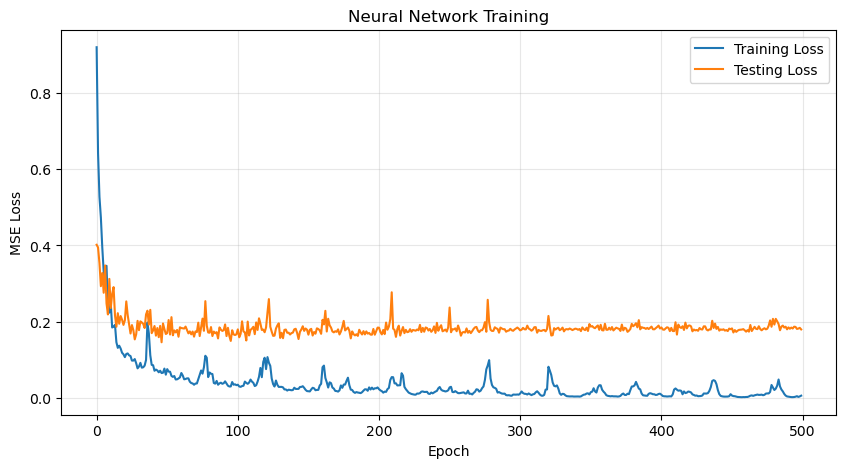

In [358]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(test_losses, label="Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Neural Network Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [359]:
model.eval()

with torch.no_grad():
    Y_pred = model(torch.tensor(X_test, dtype=torch.float32)).numpy()

# Reverse target standardization, if you standardized Y
Y_pred = np.round(Y_pred * std_y + mean_y)
Y_actual = Y_test * std_y + mean_y

# Calculate and print the mean squared error
mse = ((Y_pred - Y_actual) ** 2).mean()
print("Mean Squared Error:", mse)

Mean Squared Error: 2308.3062


In [360]:

# Make a six month forecast for cases in a region
# REGION = "CHIANG_MAI"  # Change region

region_df = df_dict[REGION]
last_window = region_df.iloc[-6 - window_size : -6]

START_DATE = region_df["date"].iloc[-6].strftime("%m-%d-%Y")
END_DATE = region_df["date"].iloc[-1].strftime("%m-%d-%Y")


x = last_window[input_cols].to_numpy(dtype=np.float32)
# Standardize the input data using the training data statistics
x = (x - mean_x) / std_x
# Convert the standardized input data to a PyTorch tensor with an additional batch dimension
x = torch.tensor(x, dtype=torch.float32).unsqueeze(0)

model.eval()
with torch.no_grad():
    y_pred = model(x).squeeze(0)
    # convert predicted values back to original scale
    y_pred = y_pred * std_y + mean_y
    # Round numbers to the nearest integer
    y_pred = torch.round(y_pred)

y_actual = region_df["dengue_total"].iloc[-6:].to_numpy(dtype=np.float32)

print(f"Predicted cases in {REGION} from {START_DATE} to {END_DATE}:\n", y_pred.numpy())
print(f"Actual cases in {REGION} from {START_DATE} to {END_DATE}:\n", y_actual)

Predicted cases in BANGKOK from 07-01-2022 to 12-01-2022:
 [ 328.  531.  826. 1159. 1293.  902.]
Actual cases in BANGKOK from 07-01-2022 to 12-01-2022:
 [ 346.  522.  807. 1114. 1246.  873.]
